# Checkpoint 2 — Optotagging validity, hardware effects, and waveform morphology

Load the saved results from `WD_BLACK`: 28 sessions, 8,415 QC-eligible units, 1,127 screen-positive candidates. The hardware-period labels follow Allen's documented LED-to-laser session cutoff; light intensity and other protocol factors differ.

In [1]:
from pathlib import Path
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

ROOT = Path(os.environ.get("SPIKES2SLOPE_DATA", "/Volumes/WD_BLACK/Spikes2Slope"))
SOURCE = ROOT / "opto_results" / "all_opto_unit_results.csv"
if not SOURCE.is_file():
    raise FileNotFoundError(f"Connect WD_BLACK or set SPIKES2SLOPE_DATA: {SOURCE}")
df = pd.read_csv(SOURCE)
required = {"unit_id", "ecephys_session_id", "cre_line", "evoked_rate_hz",
            "baseline_rate_hz", "n_pulses", "matched_candidate", "snr_qc"}
assert required.issubset(df.columns), f"Missing columns: {required - set(df.columns)}"
assert df.unit_id.is_unique, "Expected one row per unit"
for flag in ["matched_candidate", "snr_qc"]:
    df[flag] = df[flag].astype(str).str.lower().map(
        {"true": True, "false": False, "1": True, "0": False})
    assert df[flag].notna().all(), f"Unexpected values in {flag}"
df["hardware"] = np.where(df.ecephys_session_id < 789848216, "LED", "Laser")
order = ["LED", "Laser"]
colors = {"LED": "#0072B2", "Laser": "#D55E00"}
sns.set_theme(style="whitegrid", context="notebook")
eligible = df.loc[df.snr_qc].copy()
candidates = df.loc[df.matched_candidate].copy()
assert (candidates.snr_qc).all()
session = df.groupby(["ecephys_session_id", "hardware", "cre_line"], as_index=False).agg(
    eligible=("snr_qc", "sum"), candidates=("matched_candidate", "sum"),
    n_pulses=("n_pulses", "first"))
session["yield_pct"] = np.where(session.eligible > 0,
                                100 * session.candidates / session.eligible, np.nan)
means = candidates.groupby("ecephys_session_id").evoked_rate_hz.mean().rename("mean_evoked_hz")
session = session.merge(means, on="ecephys_session_id", how="left")
assert session.groupby("ecephys_session_id").size().eq(1).all()
print(f"{len(session)} sessions, {len(eligible):,} QC-eligible units, {len(candidates):,} candidates.")
print("Hardware assignment: inherited session-period proxy; not independently verified.")

28 sessions, 8,415 QC-eligible units, 1,127 candidates.
Hardware assignment: inherited session-period proxy; not independently verified.


## 1. Are our optotagging candidates reliably light-responsive?

**Current screen:** Evoked rate / (baseline rate + 1) > 2, using [+1, +9) ms after light onset and [−10, −2) ms before onset. Allen presents a “2x increase in firing rate” as an *example screening threshold*, not proof of cell identity. [AllenSDK optotagging tutorial](https://allensdk.readthedocs.io/en/latest/_static/examples/nb/ecephys_optotagging.html).

**Liz's question:** Can a single spike count as tagged? A single spike across many presentations is not evidence of a *repeatable* response. We now inspect the actual pulse-aligned spike trains, rather than aggregate rates alone.

In [2]:
%%capture opto_audit_output
import h5py

opto_cache = ROOT / "allen_visual_coding_data"
opto_baseline = (-0.010, -0.002)
opto_evoked = (0.001, 0.009)
opto_control = (-0.110, -0.102)
opto_width_s = 0.008
opto_guard_s = 0.100  # Flag any baseline beginning <100 ms after an optical epoch.


def opto_nwb_path(session_id):
    return opto_cache / f"session_{session_id}" / f"session_{session_id}.nwb"


def opto_read_epochs(nwb):
    # This NWB table is the source of AllenSDK's optogenetic_stimulation_epochs.
    table = nwb["processing/optotagging/optogenetic_stimulation"]
    return pd.DataFrame({
        "epoch_id": table["id"][:],
        **{name: table[name].asstr()[:] for name in ("stimulus_name", "condition")},
        **{name: table[name][:] for name in ("start_time", "stop_time", "duration", "level")},
    }).sort_values("start_time", kind="stable").reset_index(drop=True)


def opto_window_overlap(starts, stops, other_starts, other_stops):
    # Half-open intervals. Check every epoch, including long ramps and pulse trains.
    return ((starts[:, None] < other_stops) & (stops[:, None] > other_starts)).any(axis=1)


opto_metadata = df[["ecephys_session_id", "cre_line", "hardware", "n_pulses"]].drop_duplicates()
assert opto_metadata.ecephys_session_id.is_unique
opto_epochs_by_session, opto_pulses_by_session = {}, {}
opto_audit_rows = []
for record in opto_metadata.sort_values("ecephys_session_id").itertuples(index=False):
    sid = record.ecephys_session_id
    with h5py.File(opto_nwb_path(sid), "r") as nwb:
        epochs = opto_read_epochs(nwb)
        # Check the controls occur after the last recorded visual/spontaneous presentation.
        last_presentation = max(
            group["stop_time"][:].max() for name, group in nwb["intervals"].items()
            if name.endswith("_presentations") and len(group["stop_time"])
        )
        invalid = nwb.get("intervals/invalid_times")
        invalid_start = invalid["start_time"][:] if invalid is not None else np.array([])
        invalid_stop = invalid["stop_time"][:] if invalid is not None else np.array([])

    starts, stops = epochs.start_time.to_numpy(), epochs.stop_time.to_numpy()
    assert np.isfinite(starts).all() and np.isfinite(stops).all() and (stops > starts).all()
    # Reproduce optotagcheck.ipynb's exact selection on the stored duration.
    pulses = epochs.loc[epochs.stimulus_name.eq("pulse")
                        & epochs.duration.between(0.009, 0.020, inclusive="neither")].copy()
    assert len(pulses) == record.n_pulses > 0, f"Pulse count mismatch in {sid}"
    on = pulses.start_time.to_numpy()
    off = pulses.stop_time.to_numpy()
    preceding = np.r_[-np.inf, np.maximum.accumulate(stops)[:-1]][pulses.index]
    baseline_gap = (on + opto_baseline[0]) - preceding
    control_gap = (on + opto_control[0]) - preceding
    baseline_overlap = opto_window_overlap(on + opto_baseline[0], on + opto_baseline[1],
                                           starts, stops)
    control_overlap = opto_window_overlap(on + opto_control[0], on + opto_control[1],
                                          starts, stops)
    on_light = (on + opto_evoked[0] >= on) & (on + opto_evoked[1] <= off)
    # Conservatively flag all windows crossing a marked invalid interval on any probe.
    invalid_pair = opto_window_overlap(on + opto_control[0], on + opto_evoked[1],
                                       invalid_start, invalid_stop)
    pulses["clean_pair"] = (on_light & ~baseline_overlap & ~control_overlap
                            & (baseline_gap >= opto_guard_s) & (control_gap >= opto_guard_s)
                            & (on + opto_control[0] >= last_presentation) & ~invalid_pair)
    opto_epochs_by_session[sid] = epochs
    opto_pulses_by_session[sid] = pulses
    inter_epoch_gap = starts[1:] - np.maximum.accumulate(stops)[:-1]
    opto_audit_rows.append({
        "session": sid, "Cre": record.cre_line, "period": record.hardware,
        "epochs": len(epochs), "pulses": len(pulses),
        "level counts": pulses.groupby("level").size().to_dict(),
        "min pulse ms": 1000 * (off - on).min(),
        "max pulse ms": 1000 * (off - on).max(),
        "evoked outside pulse": int((~on_light).sum()),
        "min inter-epoch gap (s)": inter_epoch_gap.min(),
        "max inter-epoch gap (s)": inter_epoch_gap.max(),
        "min baseline gap (s)": baseline_gap.min(),
        "min control gap (s)": control_gap.min(),
        "baseline overlaps": int(baseline_overlap.sum()),
        "baseline within 100 ms": int((baseline_gap < opto_guard_s).sum()),
        "control overlaps": int(control_overlap.sum()),
        "control within 100 ms": int((control_gap < opto_guard_s).sum()),
        "control overlaps visual block": int((on + opto_control[0] < last_presentation).sum()),
        "invalid pairs": int(invalid_pair.sum()),
        "clean pairs": int(pulses.clean_pair.sum()),
    })

opto_timing = pd.DataFrame(opto_audit_rows).set_index("session")
opto_conditions = (
    pd.concat(opto_epochs_by_session, names=["session", "row"]).reset_index()
    .assign(nominal_ms=lambda rows: (1000 * rows.duration).round(3))
    .groupby(["session", "stimulus_name", "condition", "nominal_ms", "level"])
    .size().rename("presentations")
)
display(opto_timing, opto_conditions)

### Are the analysis windows appropriate?

**Checked:** Verified the stimulation timing across all 28 sessions. Our baseline and evoked windows are both 8 milliseconds, the evoked window is fully inside the light pulse, and our baseline doesn't overlap previous stimulation. So the timing setup looks reasonable. One session had 11 trial pairs overlapping an annotated invalid interval. We excluded those pairs from the exploratory statistical comparisons, not the entire session. The main remaining issue is determining whether short-latency spikes near the light boundaries are genuine neuronal responses or artifacts, which could affect our final optotagging criteria.

**Still uncertain:** Pulse counts vary (45, 75, or 151), as do light levels. The 1-ms edge exclusion does not prove spikes near onset/offset are artifact-free. Major reason we cannot interpret the 261 single-spike LED candidates versus zero laser candidates as evidence that LEDs produce more false positives is because pulse count effects evoked firing rate which effects optotagging criterion.

### What do weak versus strong candidates look like?

Four reproducibly sampled candidates span **one spike, low, moderate, and high** evoked rates. The figure shows *individual trials* aligned to light onset, with the light period, baseline, and evoked windows marked. These are illustrative examples, **not a random population prevalence estimate**.

In [3]:
%%capture opto_trial_output
opto_pool = candidates.sort_values("unit_id").copy()
opto_pool["screen_evoked_count"] = np.rint(
    opto_pool.evoked_rate_hz * opto_pool.n_pulses * opto_width_s
).astype(int)
opto_pool["band"] = np.select(
    [opto_pool.screen_evoked_count.eq(1), opto_pool.evoked_rate_hz.lt(10),
     opto_pool.evoked_rate_hz.lt(50)],
    ["Single spike", "Low", "Moderate"], default="High",
)

opto_rng = np.random.default_rng(42)
opto_selected = []
for band in ["Single spike", "Low", "Moderate", "High"]:
    pool = opto_pool.loc[opto_pool.band.eq(band)]
    if pool.empty:
        continue
    for field in ("cre_line", "hardware", "ecephys_session_id"):
        unused = pool.loc[~pool[field].isin([row[field] for row in opto_selected])]
        if not unused.empty:
            pool = unused
    opto_selected.append(pool.iloc[opto_rng.integers(len(pool))])
opto_sample = pd.DataFrame(opto_selected).set_index("unit_id")
assert not opto_sample.empty


def opto_read_spikes(nwb, unit_id):
    # Read one row of the ragged NWB spike_times column, using its cumulative end indices.
    units = nwb["units"]
    (row,) = np.flatnonzero(units["id"][:] == unit_id)
    index = units["spike_times_index"]
    return units["spike_times"][index[row - 1] if row else 0:index[row]]


def opto_spike_bounds(spikes, onsets, window):
    return np.searchsorted(spikes, onsets + window[0]), np.searchsorted(spikes, onsets + window[1])


opto_trials_by_unit, opto_rasters = {}, {}
for unit_id, row in opto_sample.iterrows():
    pulses = opto_pulses_by_session[row.ecephys_session_id]
    on, off = pulses.start_time.to_numpy(), pulses.stop_time.to_numpy()
    with h5py.File(opto_nwb_path(row.ecephys_session_id), "r") as nwb:
        spikes = opto_read_spikes(nwb, unit_id)
    assert np.isfinite(spikes).all() and (np.diff(spikes) >= 0).all(), unit_id
    trials = pulses[["epoch_id", "level", "start_time", "stop_time", "clean_pair"]].copy()
    for label, event_times, window in [
        ("baseline", on, opto_baseline), ("evoked", on, opto_evoked),
        ("earlier_control", on, opto_control),
        ("onset_edge", on, (-0.001, 0.001)), ("offset_edge", off, (-0.001, 0.001)),
        ("inner_evoked", on, (0.002, 0.008)), ("inner_baseline", on, (-0.009, -0.003)),
    ]:
        left, right = opto_spike_bounds(spikes, event_times, window)
        trials[label] = right - left
        if label == "evoked":
            trials["first_evoked_ms"] = [
                1000 * (spikes[i] - onset) if i < j else np.nan
                for i, j, onset in zip(left, right, on)
            ]
    for window_name in ("baseline", "evoked"):
        raw_rate = trials[window_name].sum() / (len(trials) * opto_width_s)
        assert np.isclose(raw_rate, row[f"{window_name}_rate_hz"]), (unit_id, window_name)

    plot_left, plot_right = opto_spike_bounds(spikes, on, (-0.014, 0.016))
    opto_rasters[unit_id] = [
        (spikes[i:j] - onset) * 1000 for i, j, onset in zip(plot_left, plot_right, on)
    ]
    opto_trials_by_unit[unit_id] = trials

opto_trial_counts = pd.concat(opto_trials_by_unit, names=["unit_id", "epoch_row"])
opto_edge_checks = opto_trial_counts.groupby(level="unit_id")[
    ["onset_edge", "offset_edge", "inner_baseline", "inner_evoked", "earlier_control"]
].sum().reindex(opto_sample.index)
opto_level_checks = (opto_trial_counts.assign(evoked_trial=lambda rows: rows.evoked.gt(0))
                     .groupby(["unit_id", "level"]).evoked_trial.agg(["sum", "size"]))
display(opto_edge_checks, opto_level_checks)

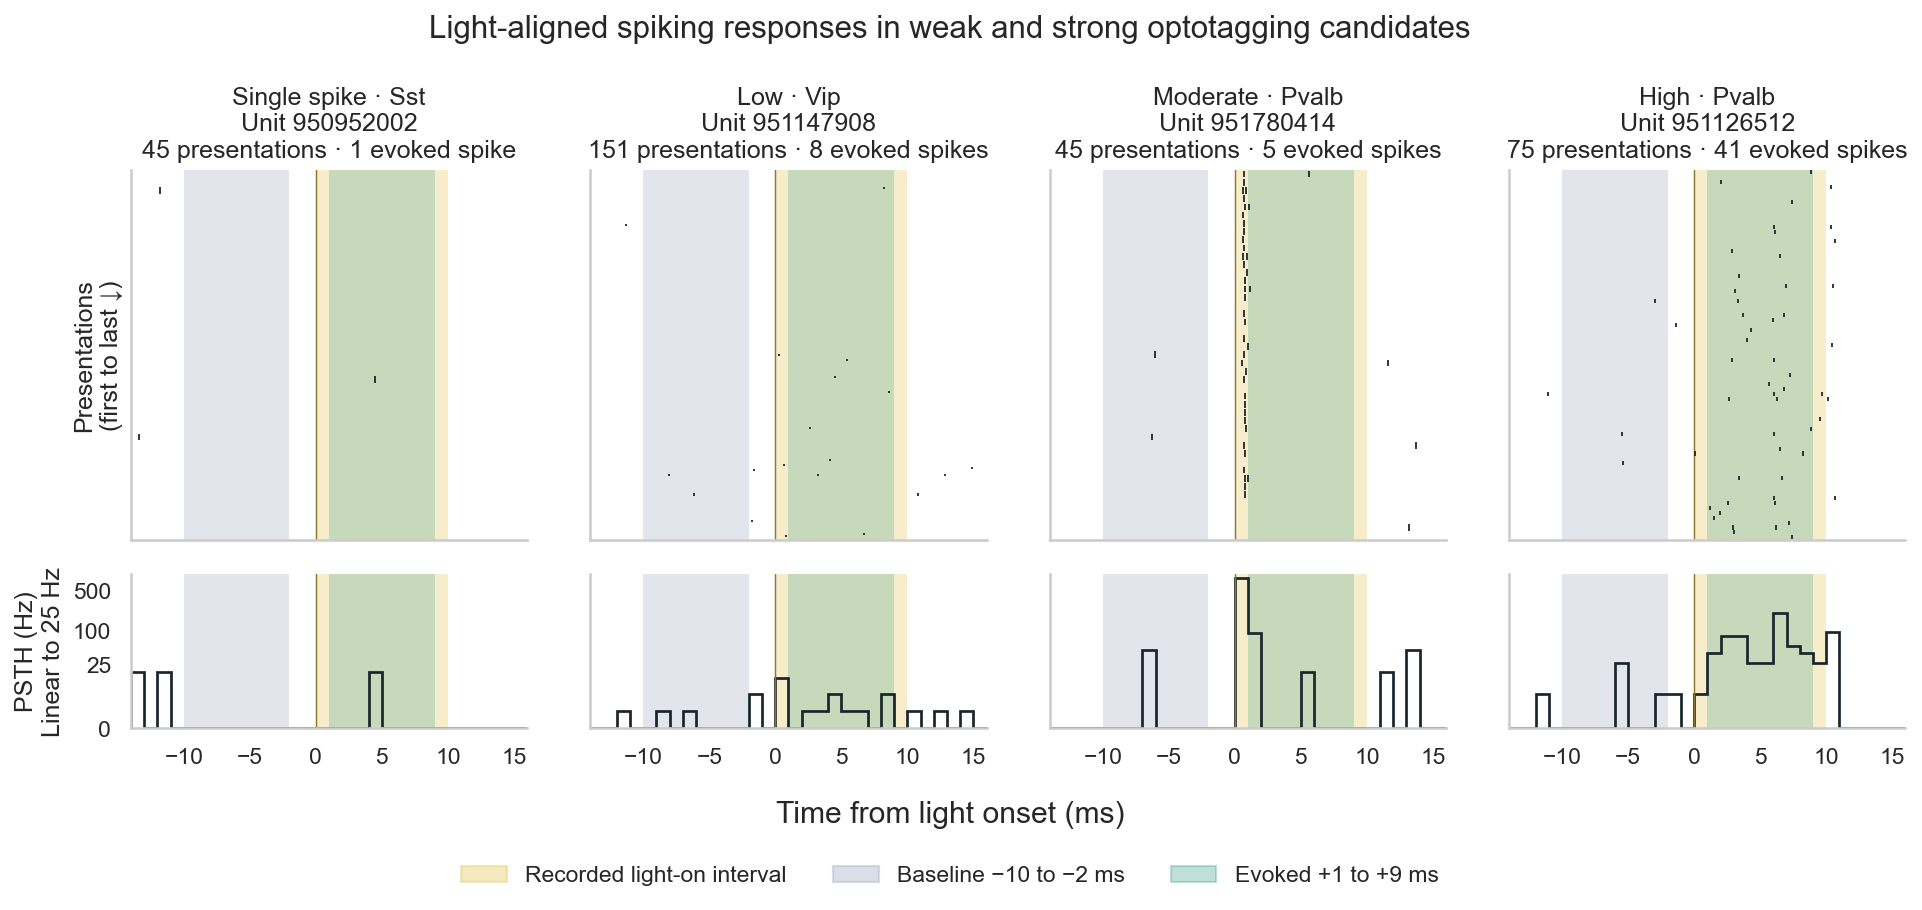

In [4]:
from matplotlib.patches import Patch

opto_light_color, opto_baseline_color, opto_evoked_color = "#e8ca62", "#9fabc0", "#55ae95"
opto_bins_ms = np.arange(-14, 17, 1)
opto_fig, opto_axes = plt.subplots(
    2, len(opto_sample), figsize=(13, 6.1), sharex=True, sharey="row",
    squeeze=False, gridspec_kw={"height_ratios": [2.4, 1]}, dpi=150,
)
opto_peak_hz = 0
for col, (unit_id, row) in enumerate(opto_sample.iterrows()):
    raster_ax, psth_ax = opto_axes[:, col]
    trials = opto_trials_by_unit[unit_id]
    relative_spikes = opto_rasters[unit_id]
    n = len(trials)
    # x uses elapsed milliseconds. y uses a fraction of the raster height.
    durations_ms = 1000 * (trials.stop_time - trials.start_time).to_numpy()
    for y, duration in enumerate(durations_ms):
        raster_ax.axvspan(0, duration, ymin=y / n, ymax=(y + 1) / n,
                         color=opto_light_color, alpha=.33, linewidth=0, zorder=0)
    psth_ax.axvspan(0, durations_ms.min(), color=opto_light_color, alpha=.33, linewidth=0)
    if np.ptp(durations_ms) > 0.001:
        psth_ax.axvspan(durations_ms.min(), durations_ms.max(),
                       color=opto_light_color, alpha=.16, linewidth=0)
    for ax in (raster_ax, psth_ax):
        for window, shade in [(opto_baseline, opto_baseline_color), (opto_evoked, opto_evoked_color)]:
            ax.axvspan(*(1000 * np.array(window)), color=shade, alpha=.30, linewidth=0)
        ax.axvline(0, color="#8e7730", lw=.7)
        ax.set_xlim(opto_bins_ms[[0, -1]])
        ax.set_xticks([-10, -5, 0, 5, 10, 15])
        ax.grid(False)
    raster_ax.eventplot(relative_spikes, lineoffsets=(np.arange(n) + .5) / n,
                        linelengths=.82 / n, linewidths=.85, colors="#18252c")
    evoked_total = trials.evoked.sum()
    spike_label = "spike" if evoked_total == 1 else "spikes"
    raster_ax.set(ylim=(1, 0),
                  title=f"{row.band} · {row.cre_line}\nUnit {unit_id}\n"
                        f"{n} presentations · {evoked_total} evoked {spike_label}")
    raster_ax.set_yticks([])
    spike_hist = np.histogram(np.concatenate(relative_spikes), bins=opto_bins_ms)[0]
    rates_hz = spike_hist / (n * .001)
    psth_ax.stairs(rates_hz, opto_bins_ms, color="#18252c", linewidth=1.3)
    opto_peak_hz = max(opto_peak_hz, rates_hz.max())

# Keep low-count examples visible on the same scale as the onset transient.
opto_psth_axis = opto_axes[1, 0]
opto_psth_axis.set_yscale("symlog", linthresh=25)
opto_psth_axis.set_yticks([0, 25, 100, 500], labels=["0", "25", "100", "500"])
opto_psth_axis.set_ylim(0, max(28, 1.20 * opto_peak_hz))

opto_axes[0, 0].set_ylabel("Presentations\n(first to last ↓)")
opto_axes[1, 0].set_ylabel("PSTH (Hz)\nLinear to 25 Hz")
opto_fig.supxlabel("Time from light onset (ms)", y=.09)
opto_fig.suptitle("Light-aligned spiking responses in weak and strong optotagging candidates",
                  fontsize=15, y=.98)
opto_fig.legend(
    handles=[Patch(color=opto_light_color, alpha=.40, label="Recorded light-on interval"),
             Patch(color=opto_baseline_color, alpha=.38, label="Baseline −10 to −2 ms"),
             Patch(color=opto_evoked_color, alpha=.38, label="Evoked +1 to +9 ms")],
    loc="lower center", bbox_to_anchor=(.5, .005), frameon=False, ncol=3,
)
sns.despine(fig=opto_fig)
opto_fig.subplots_adjust(left=.08, right=.99, top=.81, bottom=.20, wspace=.16, hspace=.13)
plt.show()

redo and make dots darker
2 spikes lrss than 1 ms impossible unit activity

Took four candidates that all passed our original optotagging criterion and aligned their spikes to individual light presentations. What stood out was how differently they responded. Our single-spike candidate responded on only one of 45 presentations, whereas our strongest candidate responded on 35 of 75. We also found one candidate with a lot of detections right around light onset, which raises an artifact concern. So I think the main takeaway is that the current rate-ratio threshold is useful for finding candidates, but we need additional reliability and artifact criteria before treating them as confirmed optotagged units.

**After the raster/PSTHs:** The single-spike unit responded on **1/45 (2.2%)** presentations; the low unit on **8/151 (5.3%)**. Neither provides strong evidence of a repeatable light response. The moderate unit responded on **5/45 (11.1%)**, but only **one evoked spike** remained in the stricter [+2, +8) ms window; **36 detections** occurred within ±1 ms of onset. Their origin is unresolved.

The high unit responded on **35/75 (46.7%)** presentations and still on **29/75 (38.7%)** after trimming, with median first-spike latency **5.64 ms**. **Main message:** Passing the same screen does **not** imply the same reliability. Four selected examples do not establish the false-positive rate.

### Is light-window spike probability greater than baseline?

The next cell runs an **exploratory paired, one-sided exact McNemar test**, comparing spike presence in equal-duration light-on and light-free windows; an earlier dark window checks control stability. Invalid pairs are omitted.

**Caution:** The same presentations helped *select* these four candidates. Consequently, these nominal p-values do **not** independently validate their tags. Confirmatory testing will need independent presentations or a selection-aware analysis, pulse-level controls, and correction across all tested units. **No threshold is decided here.**

In [6]:
%%capture opto_paired_output
def opto_paired_summary(trials, evoked_col, baseline_col):
    pairs = trials.loc[trials.clean_pair]
    evoked = pairs[evoked_col].gt(0)
    baseline = pairs[baseline_col].gt(0)
    evoked_only = int((evoked & ~baseline).sum())
    baseline_only = int((baseline & ~evoked).sum())
    discordant = evoked_only + baseline_only
    nominal_p = (stats.binomtest(evoked_only, discordant, alternative="greater").pvalue
                 if discordant else 1.0 if len(pairs) else np.nan)
    return {
        "pairs": len(pairs), "first only": evoked_only, "second only": baseline_only,
        "first occupancy %": 100 * evoked.mean(), "second occupancy %": 100 * baseline.mean(),
        "difference (pp)": 100 * (evoked.mean() - baseline.mean()), "nominal p": nominal_p,
    }


opto_paired = pd.DataFrame.from_dict(
    {unit_id: opto_paired_summary(trials, "evoked", "baseline")
     for unit_id, trials in opto_trials_by_unit.items()}, orient="index",
)
opto_dark_control = pd.DataFrame.from_dict(
    {unit_id: opto_paired_summary(trials, "baseline", "earlier_control")
     for unit_id, trials in opto_trials_by_unit.items()}, orient="index",
)
opto_trimmed = pd.DataFrame.from_dict(
    {unit_id: opto_paired_summary(trials, "inner_evoked", "inner_baseline")
     for unit_id, trials in opto_trials_by_unit.items()}, orient="index",
)
display(opto_paired, opto_dark_control, opto_trimmed)

After inspecting the rasters, implemented an exploratory statistical comparison of light-on versus baseline spike probability. Also compared two light-free windows and repeated the analysis with a narrower evoked window to assess sensitivity to onset artifacts. The main limitation is that we're testing units on the same presentations used to select them, so these p-values aren't independent validation. I also found that other published optotagging methods use stricter criteria (Wei et al. (2023) uses evoked firing rate > 25 Hz & evoked response > 2.5 times baseline). An important decision should be which requirements we want to use for a separate high-confidence optotagging label.

## 2. LED versus laser: do screening-positive units respond differently?

These are **hardware-period associations among the original candidates**, not comparisons of confirmed cell types or causal hardware effects.

**How many candidates passed the screen?** Compare raw counts and candidate yield (candidates / QC-eligible units).

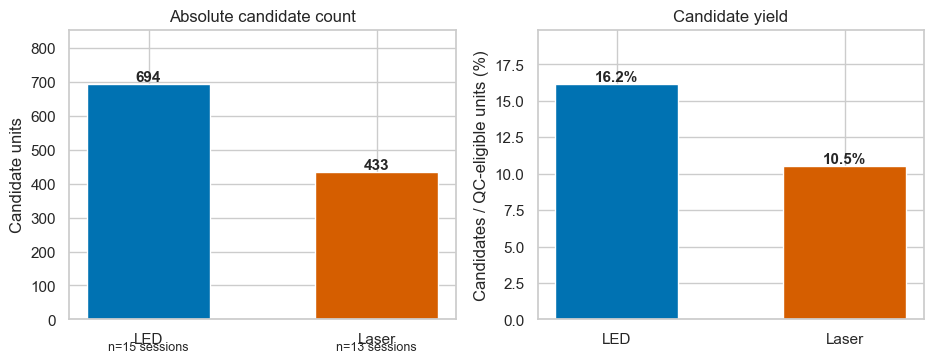

In [7]:
summary = session.groupby("hardware").agg(
    sessions=("ecephys_session_id", "size"),
    eligible=("eligible", "sum"), candidates=("candidates", "sum")).reindex(order)
summary["yield_pct"] = 100 * summary.candidates / summary.eligible
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.8))
for ax, col, ylabel in zip(axes, ["candidates", "yield_pct"],
                            ["Candidate units", "Candidates / QC-eligible units (%)"]):
    vals = summary[col].to_numpy()
    ax.bar(order, vals, color=[colors[h] for h in order], width=.54)
    for i, v in enumerate(vals):
        ax.text(i, v, f"{v:.0f}" if col=="candidates" else f"{v:.1f}%",
                ha="center", va="bottom", fontsize=11, weight="bold")
    ax.set(ylabel=ylabel); ax.set_ylim(0, max(vals)*1.23)
axes[0].set_title("Absolute candidate count")
axes[1].set_title("Candidate yield")
for i,h in enumerate(order):
    axes[0].text(i, -max(summary.candidates)*.13, f"n={summary.loc[h,'sessions']} sessions",
                 ha="center", fontsize=9)
fig.tight_layout()
plt.show()

**Result:** LED: **694/15 sessions**, 16.2% yield; laser: **433/13 sessions**, 10.5% yield. Yield means *passing our screen*, not verified tagging.

**How strong are candidate responses?** Distribution of evoked firing rates within each hardware period.

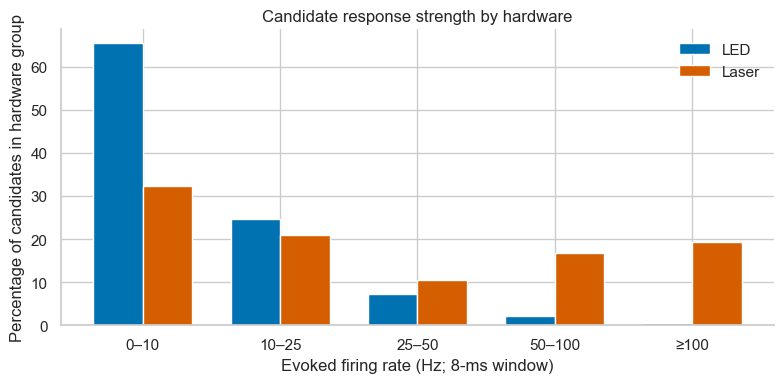

In [8]:
bins = [0, 10, 25, 50, 100, np.inf]
labels = ["0–10", "10–25", "25–50", "50–100", "≥100"]
rate_bins = candidates.assign(rate_bin=pd.cut(candidates.evoked_rate_hz,
                                              bins=bins, labels=labels, right=False))
rate_pct = (pd.crosstab(rate_bins.hardware, rate_bins.rate_bin, normalize="index")
              .reindex(index=order, columns=labels, fill_value=0) * 100)
x = np.arange(len(labels))
width = 0.36
fig, ax = plt.subplots(figsize=(8, 4))
for j,h in enumerate(order):
    bars = ax.bar(x + (j-0.5)*width, rate_pct.loc[h], width, label=h, color=colors[h])
ax.set_xticks(x, labels)
ax.set(xlabel="Evoked firing rate (Hz; 8-ms window)",
       ylabel="Percentage of candidates in hardware group",
       title="Candidate response strength by hardware")
ax.legend(frameon=False)
sns.despine()
fig.tight_layout()
plt.show()

**Result:** Candidate median evoked rate: **5.56 Hz (LED)** versus **21.67 Hz (laser)**. Candidate observations within sessions are not independent. 

Found substantially higher evoked firing rates in the laser recordings, even at the session level. But that doesn't necessarily mean laser gives us better optotagging labels. The difference could reflect stronger stimulation, our candidate-selection threshold, or other protocol differences. I don't think we have enough evidence to exclude LED yet. Instead, I'd suggest applying stronger optotagging validation criteria to both groups and comparing which units survive

**Does this persist at the session level?** Each dot represents a recording session; Welch tests the mean difference and Mann–Whitney compares ranks.

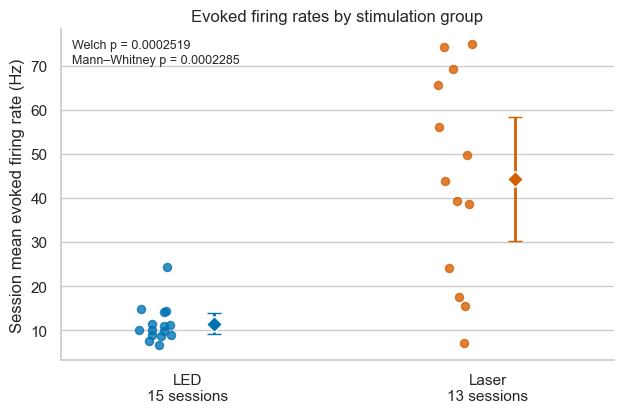

In [9]:
rate_sessions = session.dropna(subset=["mean_evoked_hz"]).copy()
rate_groups = {h: rate_sessions.loc[rate_sessions.hardware.eq(h), "mean_evoked_hz"]
               for h in order}

s = session.dropna(subset=["mean_evoked_hz"]).copy()
a = s.loc[s.hardware.eq("LED"), "mean_evoked_hz"].to_numpy()
b = s.loc[s.hardware.eq("Laser"), "mean_evoked_hz"].to_numpy()
test = stats.ttest_ind(a, b, equal_var=False)

def welch_session_comparison(led, laser, result=None):
    led, laser = np.asarray(led), np.asarray(laser)
    difference = led.mean() - laser.mean()
    v_led = led.var(ddof=1) / len(led)
    v_laser = laser.var(ddof=1) / len(laser)
    dof = (v_led + v_laser)**2 / (
        v_led**2 / (len(led) - 1) + v_laser**2 / (len(laser) - 1))
    margin = stats.t.ppf(.975, dof) * np.sqrt(v_led + v_laser)
    if result is None:
        result = stats.ttest_ind(led, laser, equal_var=False)
    return {"difference_hz": difference, "ci_low_hz": difference - margin,
            "ci_high_hz": difference + margin, "df": dof,
            "t": result.statistic, "p": result.pvalue}


led_rates, laser_rates = (rate_groups[h] for h in order)
welch_rates = welch_session_comparison(led_rates, laser_rates, result=test)
rank_rates = stats.mannwhitneyu(led_rates, laser_rates, alternative="two-sided",
                               method="asymptotic")
def plot_session_rates(ax, rows, rng):
    for i, h in enumerate(order):
        values = rows.loc[rows.hardware.eq(h), "mean_evoked_hz"]
        ax.scatter(i + rng.uniform(-.17, -.05, len(values)), values,
                   color=colors[h], s=34, alpha=.78)
        if len(values) >= 2:
            margin = stats.t.ppf(.975, len(values) - 1) * stats.sem(values)
            ax.errorbar(i + .09, values.mean(), yerr=margin, fmt="D", color=colors[h],
                        markeredgecolor="white", markersize=8, capsize=5, linewidth=2)
        elif len(values) == 1:
            ax.plot(i + .09, values.iloc[0], marker="D", color=colors[h])
    counts = rows["hardware"].value_counts()
    ax.set_xticks(range(len(order)), [f"{h}\n{counts.get(h, 0)} sessions" for h in order])
    ax.set(xlim=(-.42, 1.42))
    ax.grid(axis="x", visible=False)


fig, ax = plt.subplots(figsize=(6.4, 4.3))
plot_session_rates(ax, rate_sessions, np.random.default_rng(42))
ax.set(ylabel="Session mean evoked firing rate (Hz)",
       title="Evoked firing rates by stimulation group")
ax.text(.02, .97, f"Welch p = {welch_rates['p']:.4g}\nMann–Whitney p = {rank_rates.pvalue:.4g}",
        transform=ax.transAxes, va="top", fontsize=9)
sns.despine(fig=fig)
fig.tight_layout()
plt.show()

**Result:** LED − laser session-mean difference **−32.83 Hz** (95% CI −47.00 to −18.67; Welch *p* = 0.000252); Mann–Whitney *p* = 0.000228. This is an **association**, not a controlled hardware experiment.

We first noticed that laser candidates had higher evoked firing rates, so we compared the groups at the session level to avoid treating neurons from the same recording as independent observations. We found a mean difference of around 33 Hz, supported by both Welch's t-test and Mann–Whitney. The association is statistically convincing, but still doesn't establish that laser produces more reliable optotagging labels or that we should exclude LED recordings.

**How many weak responses passed each screen?** Compare exactly **one evoked / zero baseline spikes** across presentations with ≤0.1 mean evoked spike per pulse. Both count units already selected as candidates.

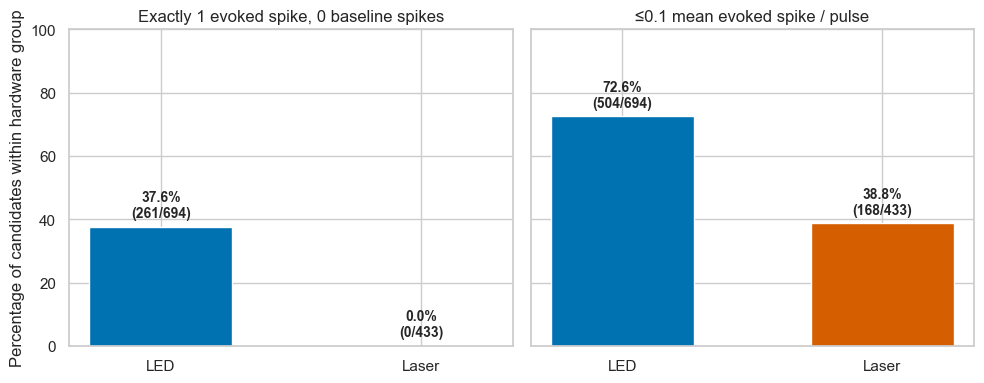

In [19]:
WINDOW_S = 0.008
# Counts are reconstructed from aggregate rates and presentation counts.
# The original processing uses 8-ms baseline and evoked windows.
candidates = candidates.copy()
candidates["evoked_total"] = np.rint(candidates.evoked_rate_hz * candidates.n_pulses * WINDOW_S).astype(int)
candidates["baseline_total"] = np.rint(candidates.baseline_rate_hz * candidates.n_pulses * WINDOW_S).astype(int)
candidates["exact_one_zero"] = (candidates.evoked_total == 1) & (candidates.baseline_total == 0)
candidates["mean_spikes_per_pulse"] = candidates.evoked_rate_hz * WINDOW_S
THRESH = 0.10  # Exploratory, NOT a validated candidate exclusion criterion
candidates["weak_per_pulse"] = candidates.mean_spikes_per_pulse <= THRESH

def summarize(flag):
    result = candidates.groupby("hardware").agg(
        total=("unit_id", "size"), matching=(flag, "sum")).reindex(order)
    result["pct"] = 100 * result.matching / result.total
    return result
exact = summarize("exact_one_zero")
comparable = summarize("weak_per_pulse")
fig, axes = plt.subplots(1, 2, figsize=(10, 4.0), sharey=True)
panels = [
    ("Exactly 1 evoked spike, 0 baseline spikes", exact),
    ("≤0.1 mean evoked spike / pulse", comparable)
]
for ax, (ttl, dat) in zip(axes, panels):
    ax.bar(order, dat.pct, width=.55, color=[colors[h] for h in order])
    for j,h in enumerate(order):
        row = dat.loc[h]
        ax.text(j, row.pct + 2, f"{row.pct:.1f}%\n({int(row.matching)}/{int(row.total)})",
                ha="center", va="bottom", fontsize=10, weight="bold")
    ax.set(title=ttl, xlabel="", ylim=(0, 100))
axes[0].set_ylabel("Percentage of candidates within hardware group")
fig.tight_layout()
plt.show()

**Result:** Exactly one spike: **261/694 LED (37.6%)**, **0/433 laser**. The pulse-count-dependent rate threshold can admit one spike with **45 pulses** but not with **75**. Using ≤0.1 spike/pulse: **72.6% LED** versus **38.8% laser**. **Do not interpret these as false-positive rates.**

Found that 37.6% of LED candidates had exactly one evoked spike and zero baseline spikes, compared with none of the laser candidates. Part of that difference comes directly from the pulse-count dependence of our selection rule. But even after comparing spikes per pulse, 72.6% of LED candidates versus 38.8% of laser candidates had very weak responses. So I think we have reason to scrutinize LED candidates more carefully, but not enough evidence to discard the entire hardware group

**What if laser candidates have higher firing rates simply because the two hardware groups contain different proportions of Pvalb, Sst, and Vip recordings?** The table summarizes sessions, yield and equal-session-mean response rate for Pvalb, Sst and Vip.

In [11]:
cre_order = ["Pvalb", "Sst", "Vip"]
cre_index = pd.MultiIndex.from_product([cre_order, order], names=["cre_line", "hardware"])
composition = session.groupby(["cre_line", "hardware"]).agg(
    sessions=("ecephys_session_id", "size"), eligible_units=("eligible", "sum"),
    candidate_units=("candidates", "sum"), session_mean_hz=("mean_evoked_hz", "mean"))
composition = composition.reindex(cre_index)
count_cols = ["sessions", "eligible_units", "candidate_units"]
composition[count_cols] = composition[count_cols].fillna(0).astype(int)
composition["yield_pct"] = (100 * composition["candidate_units"]
                            / composition["eligible_units"].replace(0, np.nan))
unit_rates = candidates.groupby(["cre_line", "hardware"])["evoked_rate_hz"].agg(
    unit_mean_hz="mean", unit_median_hz="median")
cre_composition_full = composition.join(unit_rates)
display(cre_composition_full[["sessions", "yield_pct", "session_mean_hz"]].rename(
    columns={"sessions": "Sessions", "yield_pct": "Candidate yield (%)",
             "session_mean_hz": "Mean session rate (Hz)"}).round(2))

Sessions  Candidate yield (%)  Mean session rate (Hz)
cre_line hardware                                                       
Pvalb    LED              4                13.97                   13.62
         Laser            4                17.55                   64.86
Sst      LED              8                17.25                   11.34
         Laser            4                 9.77                   53.17
Vip      LED              3                15.71                    8.82
         Laser            5                 5.94                   20.70

Wanted to check whether the hardware firing-rate difference was simply due to different Cre-line compositions. When we separated Pvalb, Sst, and Vip recordings, laser candidates still had higher average evoked firing rates in all three groups. But candidate yield was mixed: laser yielded more Pvalb candidates, while LED yielded more Sst and Vip candidates.

**Does the LED-versus-laser firing-rate difference persist when we compare recordings from the same Cre line?**

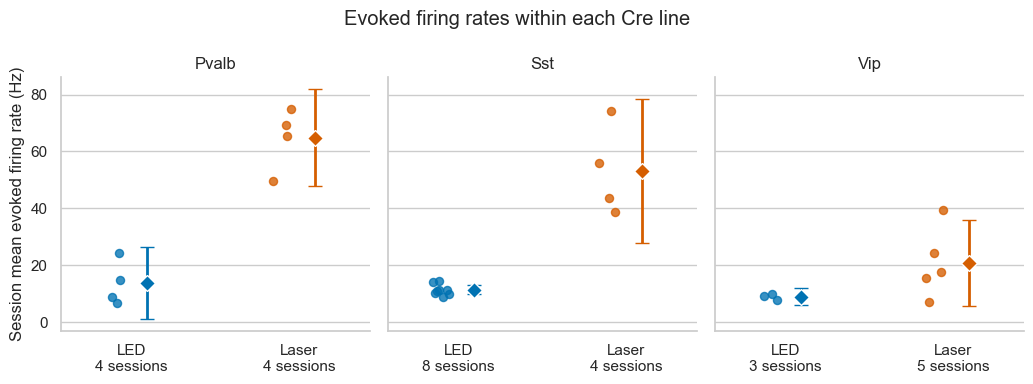

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(10.5, 3.9), sharey=True)
cre_rng = np.random.default_rng(42)
for ax, cre in zip(axes, cre_order):
    plot_session_rates(ax, rate_sessions.loc[rate_sessions.cre_line.eq(cre)], cre_rng)
    ax.set_title(cre)
axes[0].set_ylabel("Session mean evoked firing rate (Hz)")
fig.suptitle("Evoked firing rates within each Cre line")
sns.despine(fig=fig)
fig.tight_layout()
plt.show()

After separating recordings by Cre line to see whether the overall hardware difference was driven by differences in Cre-line composition, laser sessions still had higher mean evoked firing rates within Pvalb, Sst, and Vip.

**Supporting calculations (hidden):** Quality checks for our LED-versus-laser analysis

In [13]:
%%capture support_audit
# Upstream evoked window: +1 to +9 ms. Baseline window: −10 to −2 ms.
# Rates are mean spikes per pulse divided by 0.008 s. Audit saved flags.
saved_flag = df["candidate_tagged"].astype(str).str.lower().isin(["true", "1"])
response_pass = df["evoked_rate_hz"].div(df["baseline_rate_hz"] + 1).gt(2)
qc_pass = (df["presence_ratio"].ge(.95) & df["isi_violations"].le(.5)
           & df["amplitude_cutoff"].le(.1) & df["snr"].ge(1))
assert saved_flag.equals(response_pass)
assert df["snr_qc"].equals(qc_pass)
assert df["matched_candidate"].equals(response_pass & qc_pass)

session_fields = ["specimen_id", "cre_line", "n_pulses"]
assert df.groupby("ecephys_session_id")[session_fields].nunique(dropna=False).eq(1).all().all()
specimens = df.groupby("ecephys_session_id")["specimen_id"].first()
assert specimens.notna().all() and specimens.is_unique
print(f"Candidate rates available for {len(rate_sessions)}/{len(session)} sessions.")
print(f"{len(specimens)} distinct specimens across {len(session)} recording sessions.")

rate_description = rate_sessions.groupby("hardware")["mean_evoked_hz"].agg(
    n="size", mean="mean", sd="std", median="median", minimum="min",
    maximum="max", skew="skew").reindex(order)
rate_description["iqr"] = rate_sessions.groupby("hardware")["mean_evoked_hz"].agg(
    lambda rates: rates.quantile(.75) - rates.quantile(.25))
print("\nSession mean rates (Hz) and sample skewness")
print(rate_description.round(3).to_string())

fig, axes = plt.subplots(1, 3, figsize=(10.5, 3.5))
rate_bins_shared = np.histogram_bin_edges(rate_sessions["mean_evoked_hz"], bins=8)
for h, ax in zip(order, axes[1:]):
    values = rate_groups[h]
    axes[0].hist(values, bins=rate_bins_shared, histtype="stepfilled",
                 color=colors[h], alpha=.45, label=f"{h} (n={len(values)})")
    (quantiles, ordered), (slope, intercept, _) = stats.probplot(values, dist="norm")
    ax.scatter(quantiles, ordered, color=colors[h], s=26)
    ax.plot(quantiles, intercept + slope * quantiles, color="0.45", linewidth=1)
    ax.set(title=f"{h} normal Q–Q (n={len(values)})", xlabel="Theoretical quantiles",
           ylim=(0, 1.08 * rate_sessions["mean_evoked_hz"].max()))
axes[0].set(title="Session rate distributions", xlabel="Session mean rate (Hz)",
            ylabel="Recording sessions")
axes[0].legend(frameon=False)
axes[1].set_ylabel("Session mean rate (Hz)")
axes[2].tick_params(labelleft=False)
sns.despine(fig=fig)
fig.tight_layout()
plt.show()
print("Welch comparison (LED − laser)")
print(pd.Series(welch_rates).to_string(float_format=lambda value: f"{value:.7g}"))
print(f"\nMann–Whitney U (LED group) = {rank_rates.statistic:g}, p = {rank_rates.pvalue:.7g}")

In [14]:
%%capture support_sensitivity
def compare_session_subset(rows):
    return welch_session_comparison(
        rows.loc[rows.hardware.eq("LED"), "mean_evoked_hz"],
        rows.loc[rows.hardware.eq("Laser"), "mean_evoked_hz"],
    )


leave_one_out = pd.DataFrame({
    sid: compare_session_subset(rate_sessions.loc[rate_sessions.ecephys_session_id.ne(sid)])
    for sid in rate_sessions["ecephys_session_id"]
}).T.rename_axis("omitted_session")
print("Leave-one-session-out ranges")
print(leave_one_out[["difference_hz", "ci_high_hz", "p"]].agg(["min", "max"]).to_string())
most_influential = leave_one_out["difference_hz"].sub(welch_rates["difference_hz"]).abs().idxmax()
print(f"Largest shift in the mean difference after omitting session {most_influential}.")

top_laser = rate_sessions.loc[rate_sessions.hardware.eq("Laser")].nlargest(2, "mean_evoked_hz")
trimmed_welch = compare_session_subset(rate_sessions.drop(top_laser.index))
print(f"\nOmit the two highest-rate laser sessions ({', '.join(top_laser.ecephys_session_id.astype(str))})")
print(pd.Series(trimmed_welch).to_string(float_format=lambda value: f"{value:.7g}"))

count_rows = []
for h, group in rate_sessions.groupby("hardware", sort=False):
    count_rows.append({
        "hardware": h,
        "candidate_min": group["candidates"].min(),
        "candidate_median": group["candidates"].median(),
        "candidate_max": group["candidates"].max(),
        "equal_session_mean_hz": group["mean_evoked_hz"].mean(),
        "candidate_weighted_mean_hz": np.average(group["mean_evoked_hz"], weights=group["candidates"]),
        "count_rate_spearman_rho": stats.spearmanr(group["candidates"], group["mean_evoked_hz"]).statistic,
    })
print("\nCandidate counts and descriptive weighting sensitivity")
print(pd.DataFrame(count_rows).set_index("hardware").reindex(order).round(3).to_string())

print("\nNumber of sessions by stimulation presentation count")
print(pd.crosstab(rate_sessions.hardware, rate_sessions.n_pulses).reindex(order).to_string())

protocol = pd.read_csv(ROOT / "opto_protocol_summary.csv")
protocol_by_hardware = rate_sessions.merge(
    protocol, on=["ecephys_session_id", "cre_line"], how="left", validate="one_to_one")
assert protocol_by_hardware["ten_ms_pulses"].eq(protocol_by_hardware["n_pulses"]).all()
print("\nSession counts by saved light-level settings (calibration unresolved)")
print(pd.crosstab(protocol_by_hardware.hardware, protocol_by_hardware.light_levels).reindex(order).to_string())

In [15]:
%%capture support_regression
import statsmodels.formula.api as smf

print(cre_composition_full.round(3).to_string())

cre_overlap = (pd.crosstab(rate_sessions["cre_line"], rate_sessions["hardware"])
               .reindex(index=cre_order, columns=order, fill_value=0))
print("\nSessions with candidate rates by Cre line")
print(cre_overlap.to_string())
assert cre_overlap.gt(0).all().all(), "A Cre line lacks hardware overlap"
model = smf.ols(
    'mean_evoked_hz ~ C(hardware, Treatment(reference="Laser"))'
    ' + C(cre_line, Treatment(reference="Pvalb"))',
    data=rate_sessions,
)
assert len(model.endog) == len(rate_sessions)
model_rank = np.linalg.matrix_rank(model.exog)
assert model_rank == model.exog.shape[1], "The model design is rank deficient"
adjusted = model.fit(cov_type="HC3", use_t=True)
hardware_term = 'C(hardware, Treatment(reference="Laser"))[T.LED]'
adjusted_difference = adjusted.params[hardware_term]
ci_low, ci_high = adjusted.conf_int().loc[hardware_term]
print(f"\nEqual-session OLS with HC3 SEs (n={int(adjusted.nobs)}, design rank={model_rank}, "
      f"residual df={adjusted.df_resid:g})")
print(f"LED − laser adjusted for Cre line: {adjusted_difference:.4f} Hz "
      f"(95% CI {ci_low:.4f} to {ci_high:.4f}, p={adjusted.pvalues[hardware_term]:.7g})")
print(f"Adjusted minus unadjusted contrast: {adjusted_difference - welch_rates['difference_hz']:+.4f} Hz")

within_cre = pd.DataFrame({
    cre: compare_session_subset(rows)
    for cre, rows in rate_sessions.groupby("cre_line")
    if cre_overlap.loc[cre].ge(3).all()
}).T.reindex(cre_order)
print("\nExploratory within-Cre differences (LED − laser, unadjusted 95% CIs)")
print(within_cre.reindex(columns=["difference_hz", "ci_low_hz", "ci_high_hz"]).round(3).to_string())

ran several supporting analyses to make sure the hardware difference wasn't an artifact of our analysis choices. We verified our candidate labels, examined the firing-rate distributions, removed individual high-rate sessions, and adjusted for Cre line. The laser-associated firing-rate difference persisted across these checks.

## Waveform morphology — exploratory cell-type correspondence


**Do candidate classes show different spike shapes?** Peak-channel, trough-aligned and amplitude-normalized mean waveforms from selected Pvalb, Sst and Vip candidate units. All identities remain provisional.

/Users/keanuventura/miniforge3/envs/allen_env/lib/python3.10/site-packages/hdmf/spec/namespace.py:531: UserWarning: Ignoring cached namespace 'hdmf-common' version 1.1.3 because version 1.8.0 is already loaded.
  warn("Ignoring cached namespace '%s' version %s because version %s is already loaded."
/Users/keanuventura/miniforge3/envs/allen_env/lib/python3.10/site-packages/hdmf/spec/namespace.py:531: UserWarning: Ignoring cached namespace 'core' version 2.2.2 because version 2.6.0-alpha is already loaded.
  warn("Ignoring cached namespace '%s' version %s because version %s is already loaded."
/Users/keanuventura/miniforge3/envs/allen_env/lib/python3.10/site-packages/hdmf/spec/namespace.py:531: UserWarning: Ignoring cached namespace 'hdmf-common' version 1.1.3 because version 1.8.0 is already loaded.
  warn("Ignoring cached namespace '%s' version %s because version %s is already loaded."
/Users/keanuventura/miniforge3/envs/allen_env/lib/python3.10/site-packages/hdmf/spec/namespace.py:531

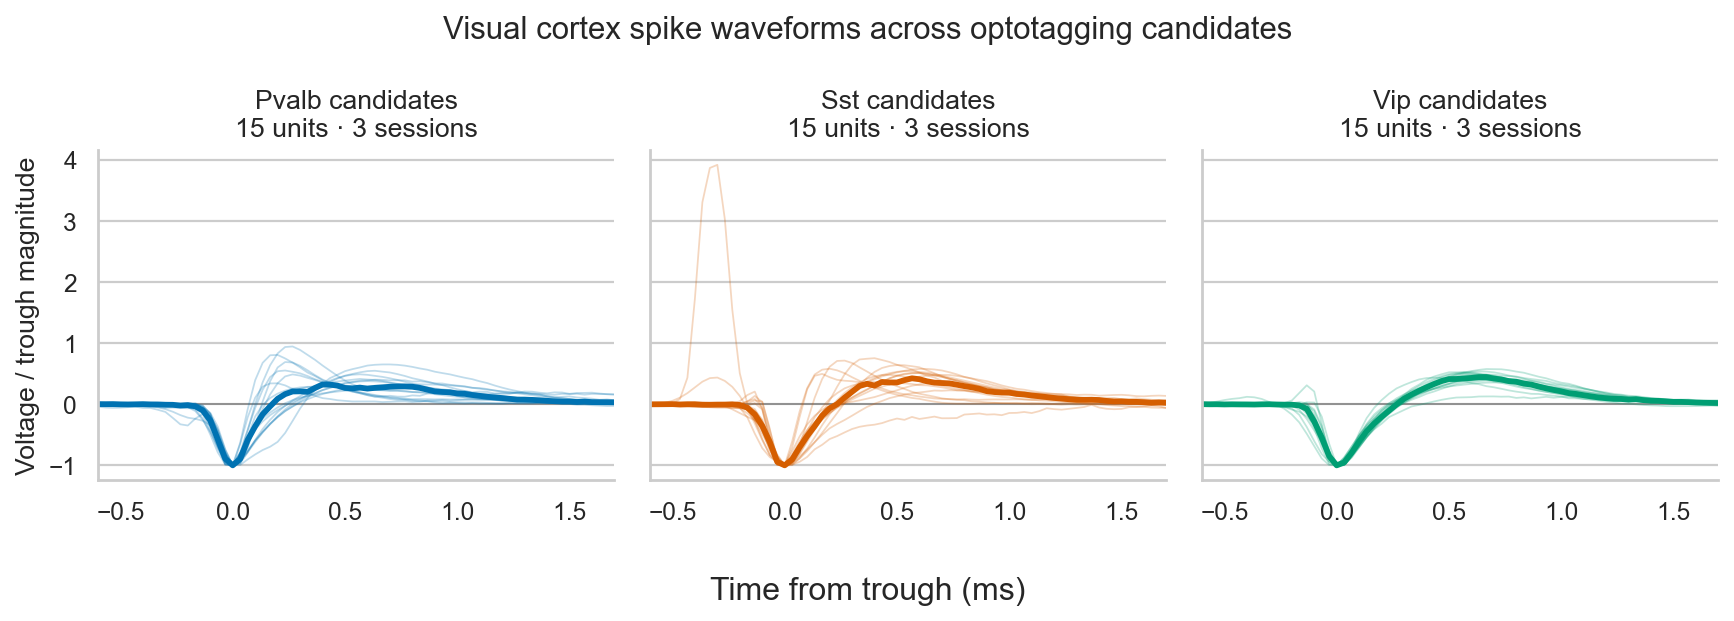

In [16]:
from collections import Counter
from pathlib import Path
import os

import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from allensdk.brain_observatory.ecephys.ecephys_session import EcephysSession
from allensdk.brain_observatory.ecephys.ecephys_session_api.ecephys_nwb_session_api import (
    EcephysNwbSessionApi,
)
from pynwb import NWBHDF5IO


def aligned_peak_trace(unit_id, units, waveforms):
    if unit_id not in units.index or unit_id not in waveforms:
        raise ValueError("unit or mean waveform missing")
    peak_channel = units.at[unit_id, "peak_channel_id"]
    try:
        trace = waveforms[unit_id].sel(channel_id=peak_channel)
    except KeyError as exc:
        raise ValueError("peak channel missing") from exc

    voltage = np.asarray(trace.values, dtype=float)
    if "time" not in trace.coords:
        raise ValueError("time coordinates missing")
    time_ms = np.asarray(trace["time"].values, dtype=float) * 1000
    if (voltage.shape != time_ms.shape or voltage.ndim != 1 or voltage.size < 3
            or not np.isfinite(voltage).all() or not np.isfinite(time_ms).all()
            or not (np.diff(time_ms) > 0).all()):
        raise ValueError("invalid voltage or time coordinates")

    trough = int(np.argmin(voltage))
    if trough in (0, voltage.size - 1) or voltage[trough] >= 0:
        raise ValueError("no interior negative trough")
    return time_ms - time_ms[trough], voltage / abs(voltage[trough])


def sample_waveforms(pool, cache_dir, rng, target=15, per_session=5):
    groups = pool.groupby("ecephys_session_id", sort=True)
    sampled, skipped = [], Counter()
    for session_id in rng.permutation(list(groups.groups)):
        nwb_path = cache_dir / f"session_{session_id}" / f"session_{session_id}.nwb"
        if not nwb_path.is_file():
            skipped["session NWB missing"] += 1
            continue

        unit_ids = rng.permutation(np.sort(groups.get_group(session_id)["unit_id"]))
        session_count = 0
        # Buffer one read-only session at a time to avoid repeated reads from the drive.
        try:
            with (h5py.File(nwb_path, "r", driver="core", backing_store=False) as h5,
                  NWBHDF5IO(file=h5, mode="r", load_namespaces=True) as io):
                ecephys = EcephysSession(api=EcephysNwbSessionApi.from_nwbfile(io.read()))
                units, waveforms = ecephys.units, ecephys.mean_waveforms
                for unit_id in unit_ids:
                    try:
                        time_ms, voltage = aligned_peak_trace(unit_id, units, waveforms)
                    except ValueError as exc:
                        skipped[str(exc)] += 1
                        continue
                    sampled.append((session_id, unit_id, time_ms, voltage))
                    session_count += 1
                    if session_count == per_session or len(sampled) == target:
                        break
                del units, waveforms, ecephys
        except OSError as exc:
            skipped["session NWB unreadable"] += 1
            print(f"Session {session_id}: {exc}")
        if len(sampled) == target:
            break
    return sampled, skipped


waveform_root = Path(os.environ.get("SPIKES2SLOPE_DATA", "/Volumes/WD_BLACK/Spikes2Slope"))
opto = pd.read_csv(waveform_root / "opto_results" / "all_opto_unit_results.csv")
matched = opto["matched_candidate"].astype(str).str.strip().str.lower().isin(["true", "1"])
visual_candidates = opto.loc[matched & opto["region"].str.startswith("VIS", na=False)]
waveform_colors = {"Pvalb": "#0072B2", "Sst": "#D55E00", "Vip": "#009E73"}
waveform_rng = np.random.default_rng(42)
waveform_samples = {}
for candidate_class in waveform_colors:
    pool = visual_candidates.loc[visual_candidates["cre_line"].eq(candidate_class)]
    sampled, skipped = sample_waveforms(
        pool, waveform_root / "allen_visual_coding_data", waveform_rng
    )
    waveform_samples[candidate_class] = sampled
    if skipped or len(sampled) < 15:
        print(f"{candidate_class}: {len(sampled)}/15 usable waveforms. Skipped: {dict(skipped)}")

# Use only the time range shared by every trace, with no extrapolation.
aligned_times = [time for rows in waveform_samples.values() for _, _, time, _ in rows]
if not aligned_times:
    raise RuntimeError("No usable visual-cortex waveforms in the local Allen cache.")
left = max(time[0] for time in aligned_times)
right = min(time[-1] for time in aligned_times)
step = max(np.median(np.diff(time)) for time in aligned_times)
grid_ms = step * np.arange(np.ceil(left / step), np.floor(right / step) + 1)
if grid_ms.size < 3:
    raise RuntimeError("Too few shared time samples for waveform comparison.")

sns.set_theme(style="whitegrid", context="notebook")
fig, axes = plt.subplots(1, 3, figsize=(11, 3.8), sharex=True, sharey=True, dpi=160)
for ax, (candidate_class, color) in zip(axes, waveform_colors.items()):
    rows = waveform_samples[candidate_class]
    n_sessions = len({session_id for session_id, _, _, _ in rows})
    ax.axhline(0, color="0.55", linewidth=0.8)
    ax.grid(axis="x", visible=False)
    if rows:
        traces = np.array([np.interp(grid_ms, time, voltage) for _, _, time, voltage in rows])
        ax.plot(grid_ms, traces.T, color=color, linewidth=0.8, alpha=0.25)
        ax.plot(grid_ms, np.median(traces, axis=0), color=color, linewidth=2.6)
    else:
        ax.text(0.5, 0.5, "No usable waveforms", ha="center", transform=ax.transAxes)
    session_label = "session" if n_sessions == 1 else "sessions"
    ax.set(title=f"{candidate_class} candidates\n{len(rows)} units · {n_sessions} {session_label}",
           xlim=(grid_ms[0], grid_ms[-1]))

axes[0].set_ylabel("Voltage / trough magnitude")
fig.supxlabel("Time from trough (ms)")
fig.suptitle("Visual cortex spike waveforms across optotagging candidates", fontsize=14)
sns.despine(fig=fig)
fig.tight_layout()
plt.show()

plotted the mean extracellular spike waveforms for optotagging candidates across the three Cre lines. Pvalb candidates generally show narrower spikes, whereas Sst and Vip candidates have broader, overlapping waveforms. This suggests waveform features may help distinguish Pvalb-like activity, but differentiating Sst and Vip hard :( (may require additional electrophysiological features.)

**Literature:** [Neuropixels Ultra cell-type research](https://pmc.ncbi.nlm.nih.gov/articles/PMC10473688/) reported ~75% accuracy for a **three-class PV/SST/VIP classifier** using more detailed extracellular features and higher-density recordings. **That is not a demonstrated SST-vs-VIP accuracy with our three features.** The question for Liz is whether waveform features alone suffice here, or whether ISI/bursting/firing features are needed.

### Where do candidates fall within waveform groups?

Each bar represents *all* units in one K-means group. Pvalb/Sst/Vip colors show matched candidates; gray means **not identified as a matched candidate**, not confirmed excitatory.

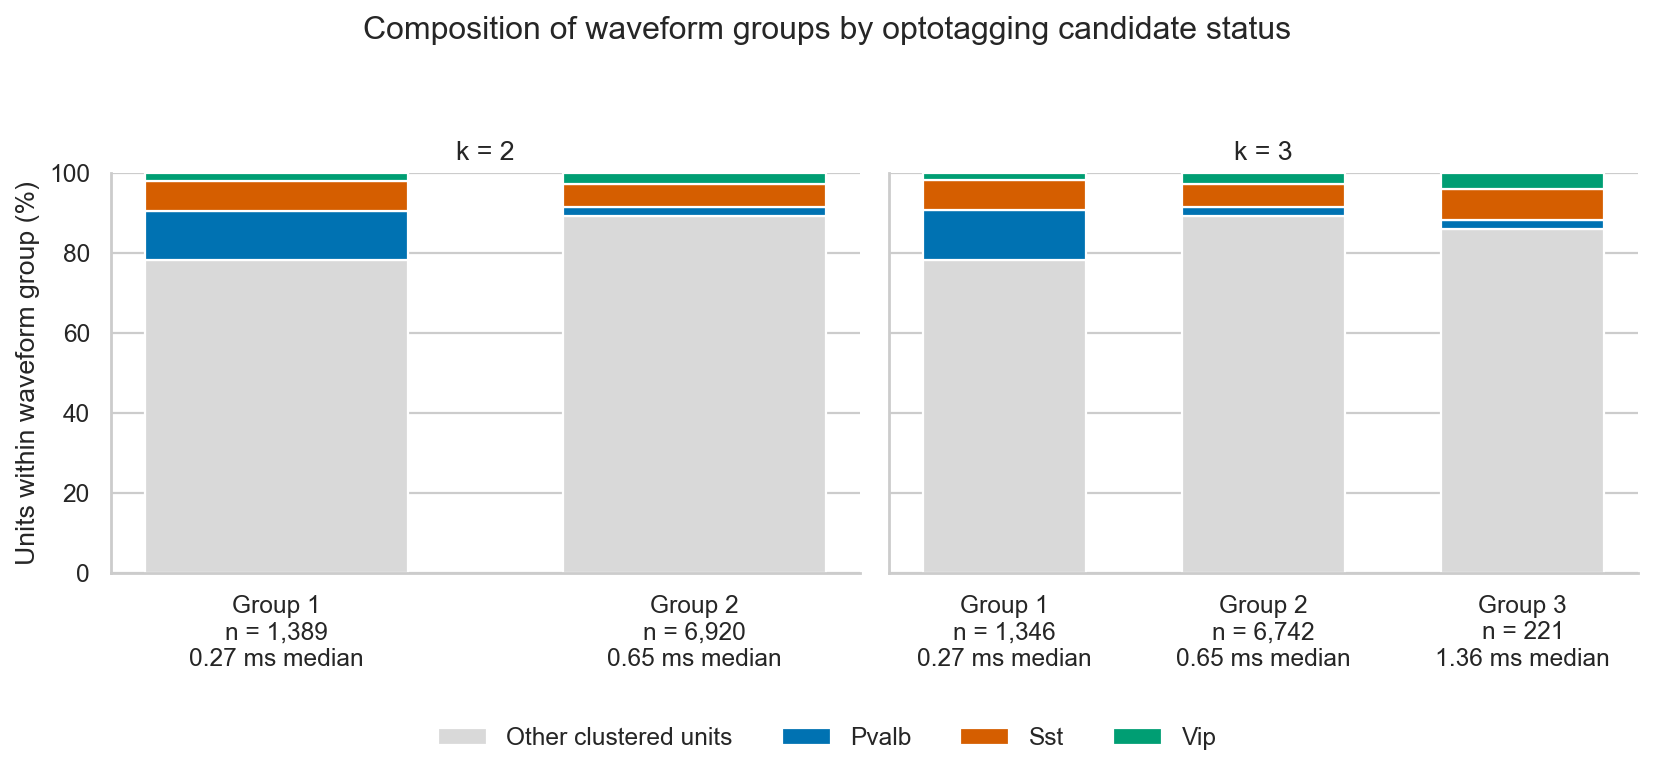

Matched 1,054 of 1,127 optotagging candidates. Excluded 73.
Outside visual cortex                  59
Missing or invalid waveform feature    14

Composition by waveform group
         Total  Median (ms)  Matched  Matched (%)  Pvalb  Sst  Vip
k Group                                                           
2 1       1389         0.27      301        21.67    170  104   27
  2       6920         0.65      753        10.88    162  396  195
3 1       1346         0.27      292        21.69    168  101   23
  2       6742         0.65      731        10.84    159  382  190
  3        221         1.36       31        14.03      5   17    9


In [18]:
# Reuse the two independently fitted models from the waveform cell above.
assignments_both = waveform_groups[["unit_id", "ecephys_session_id", "waveform_duration"]].copy()
group_columns = {k: f"waveform_group_k{k}" for k in (2, 3)}
for k, column in group_columns.items():
    medians = assignments_both.groupby(group_labels[k])["waveform_duration"].median()
    ordered = medians.sort_values().index
    assignments_both[column] = pd.Series(group_labels[k], index=assignments_both.index).map(
        {label: rank for rank, label in enumerate(ordered, start=1)}
    )

saved_k3 = pd.read_csv(results_path / "kilosort_waveform_groups.csv")
pd.testing.assert_frame_equal(
    assignments_both[["unit_id", "ecephys_session_id", "waveform_group_k3"]]
    .sort_values("unit_id").reset_index(drop=True),
    saved_k3[["unit_id", "ecephys_session_id", "waveform_group"]]
    .rename(columns={"waveform_group": "waveform_group_k3"})
    .sort_values("unit_id").reset_index(drop=True),
)

saved_both = pd.read_csv(results_path / "kilosort_waveform_groups_k2_k3.csv")
pd.testing.assert_frame_equal(
    assignments_both.drop(columns="waveform_duration").sort_values("unit_id").reset_index(drop=True),
    saved_both.sort_values("unit_id").reset_index(drop=True),
)

cre_lines = ["Pvalb", "Sst", "Vip"]
assert opto["unit_id"].notna().all() and assignments_both["unit_id"].notna().all()
joined = opto.merge(
    assignments_both.drop(columns="waveform_duration"), on="unit_id", how="left",
    validate="one_to_one", indicator=True, suffixes=("", "_assignment"),
)
assigned = joined["_merge"].eq("both")
assert joined.loc[assigned, "ecephys_session_id"].eq(
    joined.loc[assigned, "ecephys_session_id_assignment"]
).all()

candidate_flag = joined["matched_candidate"].astype(str).str.strip().str.lower().isin(["true", "1"])
valid_line = joined["cre_line"].isin(cre_lines)
matched_candidates = joined.loc[candidate_flag & valid_line & assigned].copy()
excluded = joined.loc[candidate_flag & ~(valid_line & assigned)].copy()
audit = unit_features.set_index("unit_id", verify_integrity=True)
region = excluded["unit_id"].map(audit["ecephys_structure_acronym"]).fillna(excluded["region"])
in_visual = region.str.startswith("VIS", na=False)
in_qc = excluded["unit_id"].isin(qc_visual["unit_id"])
in_features = excluded["unit_id"].isin(unit_features["unit_id"])
exclusion_reasons = np.select(
    [~excluded["cre_line"].isin(cre_lines), ~in_visual, in_qc, ~in_features],
    ["Cre line outside comparison", "Outside visual cortex", "Missing or invalid waveform feature",
     "Missing from saved feature table"],
    default="Outside the clustering QC population",
)
assert len(matched_candidates) + len(excluded) == candidate_flag.sum()

category_colors = {"Other clustered units": "#D9D9D9",
                   "Pvalb": "#0072B2", "Sst": "#D55E00", "Vip": "#009E73"}
summary_rows = []
sns.set_theme(style="whitegrid", context="notebook")
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.8), sharey=True, dpi=160)

for ax, (k, column) in zip(axes, group_columns.items()):
    full = assignments_both.groupby(column).agg(
        total=("unit_id", "size"),
        median_ms=("waveform_duration", "median"),
    )
    counts = pd.crosstab(matched_candidates[column], matched_candidates["cre_line"]).reindex(
        index=full.index, columns=cre_lines, fill_value=0
    )
    full["matched"] = counts.sum(axis=1)
    full["matched_pct"] = full["matched"].div(full["total"]).mul(100)
    counts["Other clustered units"] = full["total"] - full["matched"]
    assert counts["Other clustered units"].ge(0).all()
    assert full["matched"].sum() == len(matched_candidates)
    assert full["total"].sum() == len(assignments_both)
    percentages = counts.div(full["total"], axis=0).mul(100)
    assert np.allclose(percentages.sum(axis=1), 100)

    x = np.arange(len(full))
    bottom = np.zeros(len(full))
    for category, color in category_colors.items():
        heights = percentages[category].to_numpy()
        ax.bar(x, heights, bottom=bottom, width=.63, color=color, label=category)
        bottom += heights
    ax.set_xticks(x, [f"Group {group}\nn = {row.total:,.0f}\n{row.median_ms:.2f} ms median"
                      for group, row in full.iterrows()])
    ax.set(title=f"k = {k}", ylim=(0, 100))
    ax.grid(axis="x", visible=False)
    ax.set_axisbelow(True)
    summary_rows.append(full.join(counts[cre_lines]).rename_axis("Group"))

axes[0].set_ylabel("Units within waveform group (%)")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=4, frameon=False)
fig.suptitle("Composition of waveform groups by optotagging candidate status")
sns.despine(fig=fig)
fig.tight_layout(rect=(0, .09, 1, .93))
plt.show()

print(f"Matched {len(matched_candidates):,} of {candidate_flag.sum():,} optotagging candidates. "
      f"Excluded {len(excluded):,}.")
print(pd.Series(exclusion_reasons).value_counts().rename("Excluded").to_string())
cluster_composition = pd.concat(summary_rows, keys=group_columns, names=["k", "Group"])
print("\nComposition by waveform group")
print(cluster_composition.rename(columns={"total": "Total", "median_ms": "Median (ms)",
                                          "matched": "Matched", "matched_pct": "Matched (%)"})
      .round(2).to_string())

**Result:** Short-duration Group 1 contains **21.7%** matched candidates, including **~12% Pvalb**; Group 2 has **~10.9%** matched candidates and **~2.3% Pvalb**. These are pooled descriptive associations; they do **not** independently verify cell identity or establish that Sst and Vip can be separated.

Explored whether unsupervised waveform clustering could recover our optotagging candidate classes. Tested two and three clusters, but neither separated Pvalb, Sst, and Vip cleanly. Waveform morphology contains some useful information, but I don't think these clusters are very sufficient.

## Where do we go from here?

After going through these analyses, biggest priority is still deciding what qualifies as a reliable optotagged unit before classification.

**What does the literature suggest?**

AllenSDK: Uses a 2× firing-rate increase as an example for identifying potential optotagged units.

Wei et al. (2023): Required an evoked rate above 25 Hz and more than 2.5× baseline.

Other studies consider response latency, jitter, and consistency across light presentations.

These give possible approaches, but I don't think we should adopt a threshold without considering our specific stimulation protocol.

**Questions**

Should we require more than a firing-rate increase? For example, a minimum percentage of light presentations with a spike, alongside a statistical comparison against baseline.

How should we handle spikes near light onset? Should we use a narrower evoked window or investigate potential artifacts first?

What should we do with weak candidates? Should single-spike and low-reliability units be excluded from our training labels but retained as uncertain candidates?

Hardware?

**Proposed next step**

Finalize a set of high-confidence optotagging criteria, then apply them across our recordings while preserving the original candidate labels.

From there, return to the waveform comparison and eventually the SVM.